In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
diabetes = load_diabetes()

X = pd.DataFrame(diabetes.data,columns=diabetes.feature_names)

y = pd.Series(diabetes.target, name="Progression")

df = X.copy()
df["Progression"] = y

print("Dataset shape:", df.shape)
print(df.head())
print("\nDataset information:")
print(df.info())

Dataset shape: (442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  Progression  
0 -0.002592  0.019907 -0.017646        151.0  
1 -0.039493 -0.068332 -0.092204         75.0  
2 -0.002592  0.002861 -0.025930        141.0  
3  0.034309  0.022688 -0.009362        206.0  
4 -0.002592 -0.031988 -0.046641        135.0  

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          442 non-null 

In [5]:
print("Missing values before preprocessing:")
print(X.isnull().sum())

imputer = SimpleImputer(strategy="mean")
X_imputed = pd.DataFrame(imputer.fit_transform(X),columns=X.columns)

print("\nMissing values after preprocessing:")
print(X_imputed.isnull().sum().sum())

Missing values before preprocessing:
age    0
sex    0
bmi    0
bp     0
s1     0
s2     0
s3     0
s4     0
s5     0
s6     0
dtype: int64

Missing values after preprocessing:
0


In [6]:
X_train, X_test, y_train, y_test = train_test_split(X_imputed,y,test_size=0.2,random_state=42)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (353, 10)
Testing data shape: (89, 10)


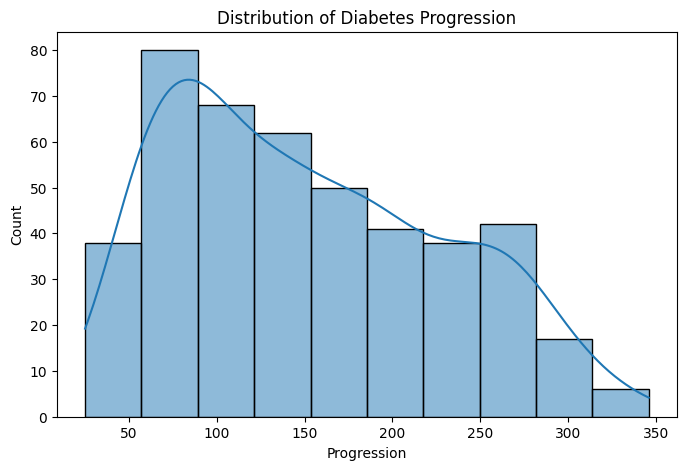

In [7]:
plt.figure(figsize=(8, 5))
sns.histplot(y, kde=True)
plt.title("Distribution of Diabetes Progression")
plt.xlabel("Progression")
plt.show()

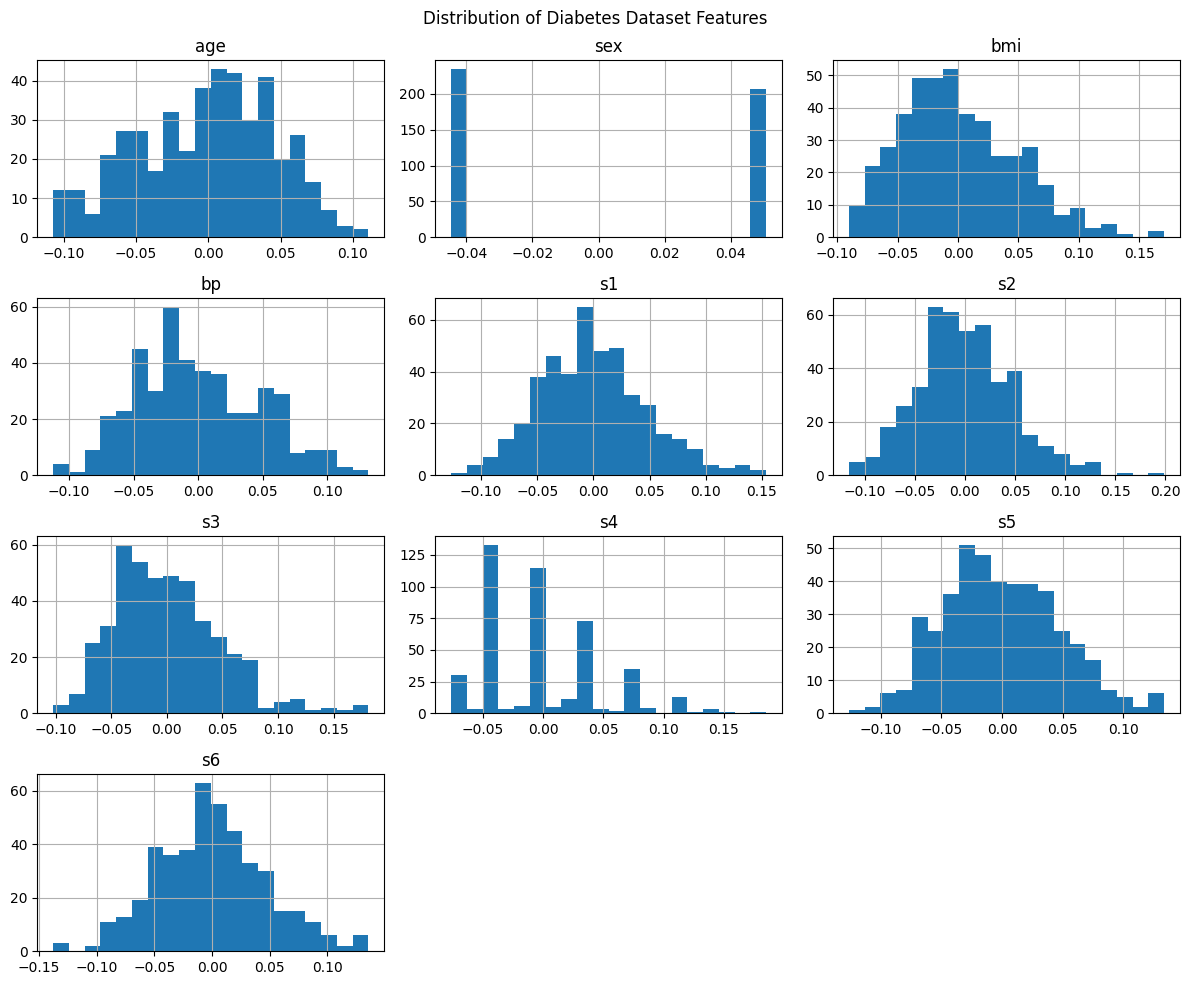

In [8]:
X.hist(figsize=(12, 10), bins=20)
plt.suptitle("Distribution of Diabetes Dataset Features")
plt.tight_layout()
plt.show()

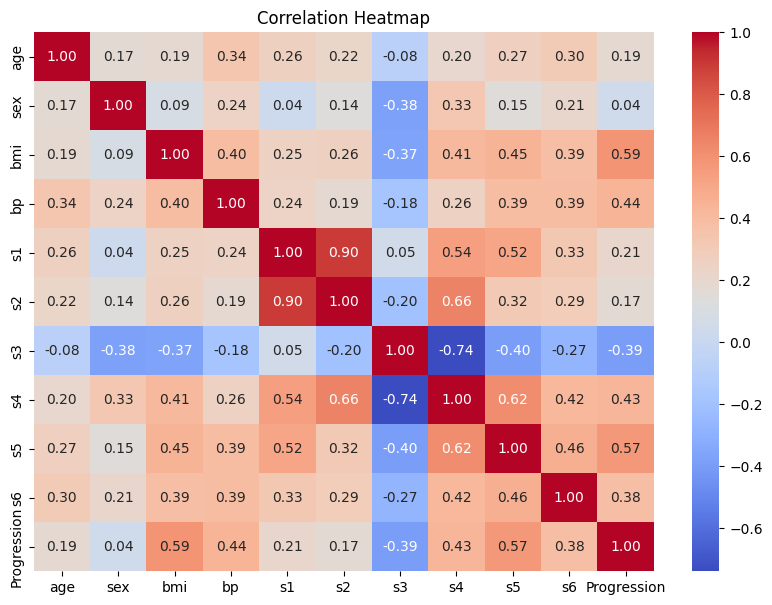

In [9]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

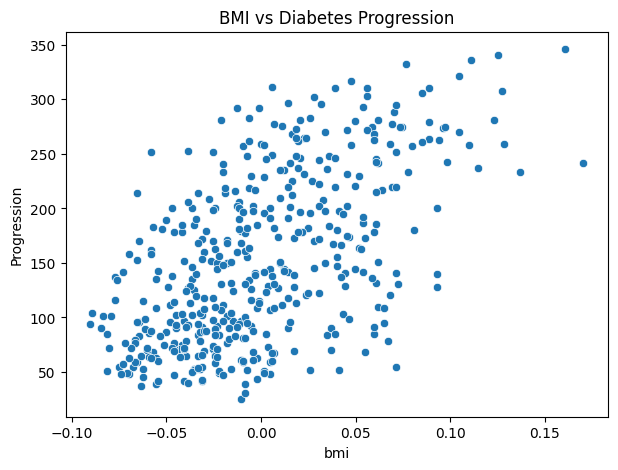

In [10]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="bmi", y="Progression")
plt.title("BMI vs Diabetes Progression")
plt.show()

In [11]:
tf.random.set_seed(42)

model = Sequential([Input(shape=(X_train_scaled.shape[1],)),Dense(32, activation="relu"),Dense(16, activation="relu"),Dense(1, activation="linear")])

model.compile(optimizer=Adam(learning_rate=0.001),loss="mse",metrics=["mae"])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
history = model.fit(X_train_scaled,y_train,epochs=100,batch_size=16,validation_split=0.2,verbose=1)

Epoch 1/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - loss: 31212.3359 - mae: 157.7445 - val_loss: 22136.3457 - val_mae: 132.8683
Epoch 2/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 30996.0000 - mae: 157.0923 - val_loss: 21948.9121 - val_mae: 132.1945
Epoch 3/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 30724.4434 - mae: 156.2692 - val_loss: 21707.6953 - val_mae: 131.3313
Epoch 4/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 30363.5039 - mae: 155.1781 - val_loss: 21385.1895 - val_mae: 130.1836
Epoch 5/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 29863.3164 - mae: 153.6858 - val_loss: 20959.9277 - val_mae: 128.6813
Epoch 6/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 29178.9922 - mae: 151.6704 - val_loss: 20414.2520 - val_mae: 126.7591
Epoch 7/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 28282.7051 - mae: 149.0310 - val_loss: 19728.0703 - val_mae: 124.3322
Epoch 8/100
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 27142.0391 - mae: 145.6360 - v

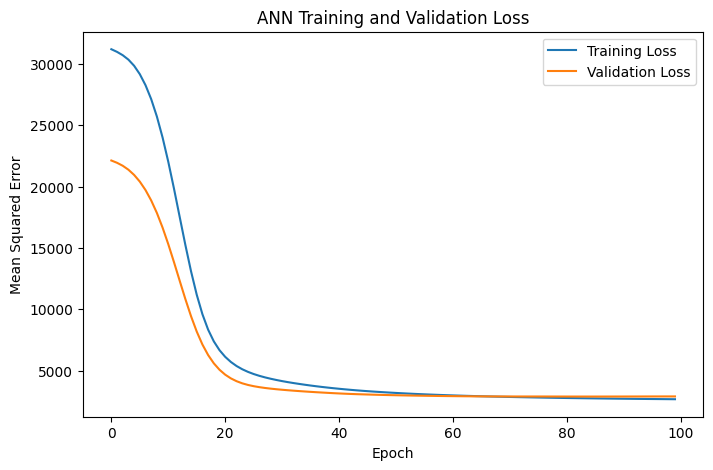

In [13]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("ANN Training and Validation Loss")
plt.legend()
plt.show()

In [14]:
y_pred = model.predict(X_test_scaled).flatten()

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 4))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Mean Squared Error: 2903.91
R2 Score: 0.4519


In [15]:
improved_model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="linear")])

improved_model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="mse",
    metrics=["mae"])

improved_history = improved_model.fit(
    X_train_scaled,
    y_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    verbose=1)

improved_pred = improved_model.predict(X_test_scaled).flatten()

improved_mse = mean_squared_error(y_test, improved_pred)
improved_r2 = r2_score(y_test, improved_pred)

print("Original model MSE:", round(mse, 2))
print("Original model R2:", round(r2, 4))
print("Improved model MSE:", round(improved_mse, 2))
print("Improved model R2:", round(improved_r2, 4))

Epoch 1/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 31558.2520 - mae: 158.8172 - val_loss: 22476.1094 - val_mae: 134.0798
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 31419.5039 - mae: 158.4048 - val_loss: 22379.3672 - val_mae: 133.7428
Epoch 3/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 31269.5137 - mae: 157.9608 - val_loss: 22250.6328 - val_mae: 133.2919
Epoch 4/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 31059.6172 - mae: 157.3442 - val_loss: 22069.4023 - val_mae: 132.6556
Epoch 5/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 30753.1992 - mae: 156.4543 - val_loss: 21810.2715 - val_mae: 131.7581
Epoch 6/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 30296.3828 - mae: 155.1420 - val_loss: 21432.3652 - val_mae: 130.4612
Epoch 7/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 29613.4297 - mae: 153.1921 - val_loss: 20880.9141 - val_mae: 128.5638
Epoch 8/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 28617.0781 - mae: 150.3235 - val_loss

   Actual Progression  Predicted Progression
0               219.0             155.960983
1                70.0             187.479050
2               202.0             150.977524
3               230.0             303.119324
4               111.0              93.214272
5                84.0             108.809677
6               242.0             275.480286
7               272.0             178.511169
8                94.0              97.795410
9                96.0              84.843628


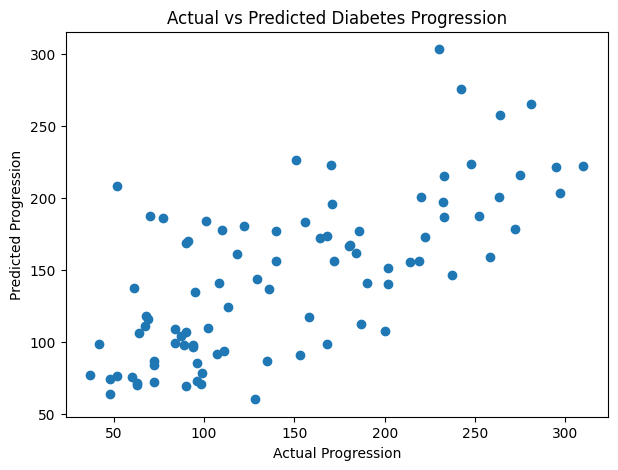

In [16]:
comparison = pd.DataFrame({
    "Actual Progression": y_test.to_numpy(),
    "Predicted Progression": improved_pred})

print(comparison.head(10))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, improved_pred)
plt.xlabel("Actual Progression")
plt.ylabel("Predicted Progression")
plt.title("Actual vs Predicted Diabetes Progression")
plt.show()

The Diabetes dataset from the sklearn library was used to develop an Artificial Neural Network for predicting diabetes progression. Data preprocessing, normalization, exploratory data analysis, model training, and evaluation were performed. The models were evaluated using Mean Squared Error and R² score. Different ANN architectures and learning rates were tested to compare their performance. The experiment demonstrates how deep learning can be applied to a regression problem, although the model is not intended for clinical diagnosis or treatment decisions.